# 05 - Correction Analysis

How deep is the current drawdown vs historical?


## Setup

In [1]:
# --- setup --------------------------------------------------------
import sys, json
sys.path.insert(0, r"D:\\Projects\\done\\eth_bot\\eth_bot_v2")
from pathlib import Path
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sqlite3

pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 60)
plt.rcParams["figure.figsize"] = (13, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
np.random.seed(42)

SYMBOL = "ETHUSDT"
OUT = Path(r"D:\\Projects\\done\\eth_bot\\eth_bot_v2") / "reports" / "forecasts"
OUT.mkdir(parents=True, exist_ok=True)
DB = Path(r"D:\\Projects\\done\\eth_bot\\eth_bot_v2") / "database" / "market.db"

def sql(q, **p):
    with sqlite3.connect(DB) as c:
        return pd.read_sql_query(q, c, params=p)

from database.config.api.binance import get_klines

def fetch(symbol, interval, limit=500):
    raw = get_klines(symbol, interval=interval, limit=limit)
    df = pd.DataFrame(raw, columns=["open_time","open","high","low","close",
        "volume","close_time","quote_volume","trades","taker_base","taker_quote","ignore"])
    df["date"] = pd.to_datetime(df["open_time"], unit="ms", utc=True).dt.tz_convert(None)
    for c in ("open","high","low","close","volume"):
        df[c] = df[c].astype(float)
    return df[["date","open","high","low","close","volume"]].set_index("date").iloc[:-1]

def action_block(name, action, reason, price=None, entry=None, stop=None,
                 target=None, conf=None, extra=None):
    print("=" * 62)
    print(f"  {name}")
    print("=" * 62)
    print(f"  time   : {datetime.now(timezone.utc).strftime('%Y-%m-%d %H:%M')} UTC")
    if price is not None: print(f"  price  : {price:,.2f}")
    if conf  is not None: print(f"  conf   : {conf:.2f}")
    print(f"  ACTION : {action}")
    print(f"  REASON : {reason}")
    if entry is not None:
        print(f"  entry  : {entry:,.2f}   stop: {stop:,.2f}   target: {target:,.2f}")
    if extra:
        for k, v in extra.items():
            print(f"  {k:<6} : {v}")
    print("=" * 62)
    return {"action": action, "reason": reason, "price": price,
            "entry": entry, "stop": stop, "target": target, "conf": conf}

## 1. Load 6y history

In [2]:
h = sql("SELECT open_time, close FROM ohlcv WHERE symbol='ETHUSDT' AND timeframe='1d' ORDER BY open_time")
h["date"] = pd.to_datetime(h.open_time, unit="ms")
h = h.set_index("date")["close"]
print("n=", len(h))

n= 2189


## 2. Drawdown series

In [3]:
peak = h.cummax()
dd = h / peak - 1
print(f"current drawdown: {dd.iloc[-1]*100:+.2f}%")
print(f"worst ever      : {dd.min()*100:+.2f}%")
print(f"on              : {dd.idxmin().date()}")

current drawdown: -44.77%
worst ever      : -79.30%
on              : 2022-06-18


## 3. Historical corrections > 20%

In [4]:
underwater = dd < -0.20
runs = []
start = None
for dt, u in underwater.items():
    if u and start is None: start = dt
    elif not u and start is not None:
        dur = (dt - start).days
        depth = dd[start:dt].min()
        runs.append({"start": start.date(), "end": dt.date(),
                     "days": dur, "depth": float(depth)})
        start = None
if start is not None:
    runs.append({"start": start.date(), "end": None, "days": (h.index[-1]-start).days,
                 "depth": float(dd[start:].min())})
pd.DataFrame(runs).tail(10)

,start,end,days,depth
11,2024-05-28,2024-06-05,8,-0.220481
12,2024-06-06,2024-12-06,183,-0.537180
13,2024-12-09,2024-12-12,3,-0.245369
14,2024-12-18,2025-07-27,221,-0.693549
15,2025-07-28,2025-08-07,10,-0.294103
16,2025-10-10,2025-10-12,2,-0.224599
17,2025-10-17,2025-10-18,1,-0.207054
18,2025-10-22,2025-10-24,2,-0.212443
19,2025-10-30,2025-11-01,2,-0.212534
20,2025-11-03,None,333,-0.675535


## 4. Chart

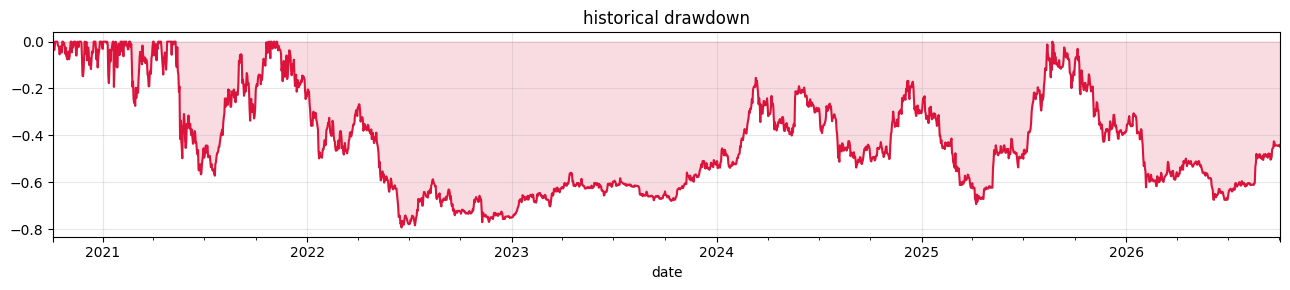

In [5]:
fig, ax = plt.subplots(figsize=(13, 3))
dd.plot(ax=ax, color="crimson", title="historical drawdown")
ax.fill_between(dd.index, dd, 0, color="crimson", alpha=0.15)
plt.tight_layout(); plt.show()

## 5. Action

In [6]:
cur_dd = float(dd.iloc[-1])
if cur_dd < -0.40: action, reason = "LONG",  "deep correction — mean reversion zone"
elif cur_dd < -0.20: action, reason = "LONG",  "moderate correction — accumulate"
elif cur_dd > -0.05: action, reason = "FLAT",  "near all-time high — no correction edge"
else:                action, reason = "FLAT",  "shallow correction"
action_block("CORRECTION", action, reason,
    price=float(h.iloc[-1]), extra={"current_dd": f"{cur_dd*100:.2f}%"})

  CORRECTION
  time   : 2026-10-04 10:42 UTC
  price  : 2,668.59
  ACTION : LONG
  REASON : deep correction — mean reversion zone
  current_dd : -44.77%


{'action': 'LONG',
 'reason': 'deep correction — mean reversion zone',
 'price': 2668.59,
 'entry': None,
 'stop': None,
 'target': None,
 'conf': None}